# Лабораторная работа 4. Attention с нуля (студенческая версия)

**Курс:** Методы обработки естественного языка · **Блок 2:** attention и архитектура трансформера

**Цель.** Реализовать scaled dot-product и multi-head attention, вывести обратный проход вручную и экспериментально проверить роль масштабирования $1/\sqrt{d_k}$, масок и позиционной информации.

**Что нужно сдать:**
1. Модуль attention (каузальная и padding-маски), совпадающий с `F.scaled_dot_product_attention` с точностью 1e-5.
2. Ручной backward attention, сверенный с autograd.
3. Эксперимент с масштабированием: энтропия attention и нормы градиентов при разных $d_k$, кривые обучения.
4. Решение трёх синтетических задач и визуализацию карт внимания.
5. Проверку перестановочной эквивариантности.

**Теория.** $\mathrm{Attn}(Q,K,V) = \mathrm{softmax}\big(QK^\top/\sqrt{d_k} + M\big)V$. Если компоненты $q, k$ независимы, с нулевым средним и единичной дисперсией, то $\mathrm{Var}(q^\top k) = d_k$, поэтому без масштабирования логиты растут как $\sqrt{d_k}$, softmax насыщается, а его якобиан $\operatorname{diag}(p) - pp^\top$ стремится к нулю.

Обратный проход для $S = QK^\top/\sqrt{d}$, $P = \mathrm{softmax}(S)$, $O = PV$:

$$ dV = P^\top dO,\quad dP = dO\,V^\top,\quad dS = P \odot \big(dP - \mathrm{rowsum}(dP \odot P)\big),\quad dQ = \tfrac{1}{\sqrt d}\, dS\, K,\quad dK = \tfrac{1}{\sqrt d}\, dS^\top Q . $$


In [14]:
# ==== Общая настройка (одинакова во всех работах) ====
import os, math, time, json, random, pathlib, urllib.request
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

FAST_DEV_RUN = True          # True — сокращённый прогон (CPU, минуты); False — полный эксперимент
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
ARTIFACTS = pathlib.Path("artifacts"); ARTIFACTS.mkdir(exist_ok=True)
DATA = pathlib.Path("data"); DATA.mkdir(exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed()

def download(url, name):
    path = DATA / name
    if not path.exists():
        urllib.request.urlretrieve(url, path)
    return path

def load_shakespeare():
    url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
    return download(url, "shakespeare.txt").read_text(encoding="utf-8")

def load_russian():
    """Русский корпус: «Война и мир» (Л. Н. Толстой), т. 1, из открытого репозитория.
    При недоступности сети используется встроенный фрагмент."""
    urls = ["https://raw.githubusercontent.com/mmcdermott/nlp-war-and-peace/master/data/war_and_peace_ru.txt",
            "https://raw.githubusercontent.com/nevmenandr/word2vec-russian-novels/master/books_before/WarAndPeace.txt"]
    for i, u in enumerate(urls):
        try:
            t = download(u, f"ru_{i}.txt").read_text(encoding="utf-8", errors="ignore")
            if len(t) > 100_000: return t
        except Exception:
            pass
    base = ("Все счастливые семьи похожи друг на друга, каждая несчастливая семья несчастлива по-своему. "
            "Всё смешалось в доме Облонских. Жена узнала, что муж был в связи с бывшею в их доме француженкою-гувернанткой, "
            "и объявила мужу, что не может жить с ним в одном доме. ")
    return base * 400

print(f"torch {torch.__version__}, device={DEVICE}, FAST_DEV_RUN={FAST_DEV_RUN}")

torch 2.12.0.dev20260408+cu128, device=cuda, FAST_DEV_RUN=True


## 1. Scaled dot-product attention и маски

Соглашения: `q, k, v` имеют форму `(B, H, T, d)`; `key_padding_mask` — булев тензор `(B, T)`, `True` означает «паддинг, не смотреть». Замаскированные логиты заменяйте на \(-\infty\). Если строка замаскирована полностью, результат не определён: в тестах таких строк нет.

In [ ]:
def sdpa(q, k, v, causal=False, key_padding_mask=None, scale=None, return_probs=False):
    d = q.size(-1)
    scale = 1 / math.sqrt(d) if scale is None else scale

    S = (q @ k.transpose(-1, -2)) * scale
    Tq, Tk = q.size(-2), k.size(-2)
    
    if causal:
        causal_mask = torch.ones(Tq, Tk, dtype=torch.bool, device=q.device).triu(1)
        S = S.masked_fill(causal_mask, float("-inf"))

    if key_padding_mask is not None:
        S = S.masked_fill(key_padding_mask[:, None, None, :], float("-inf"))

    P = S.softmax(-1)
    out = P @ v

    return (out, P) if return_probs else out

class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_head, causal=False, scale=None):
        super().__init__()
        assert d_model % n_head == 0
        self.h, self.d = n_head, d_model // n_head
        self.wq, self.wk, self.wv, self.wo = (nn.Linear(d_model, d_model, bias=False) for _ in range(4))
        self.causal, self.scale = causal, scale
        self.last_probs = None
    def forward(self, x, key_padding_mask=None):
        B, T, C = x.shape
  
        q = self.wq(x).view(B, T, self.h, self.d).transpose(1, 2)
        k = self.wk(x).view(B, T, self.h, self.d).transpose(1, 2)
        v = self.wv(x).view(B, T, self.h, self.d).transpose(1, 2)

        out, P = sdpa(q, k, v, self.causal, key_padding_mask, self.scale, return_probs=True)
        self.last_probs = P.detach()
        out = out.transpose(1, 2).contiguous().view(B, T, C)

        return self.wo(out)

In [4]:
torch.manual_seed(0)
q, k, v = (torch.randn(2, 3, 7, 16) for _ in range(3))
pad = torch.zeros(2, 7, dtype=torch.bool); pad[1, 5:] = True
for causal in (False, True):
    ref = F.scaled_dot_product_attention(q, k, v, is_causal=causal)
    assert torch.allclose(sdpa(q, k, v, causal), ref, atol=1e-5)
ref = F.scaled_dot_product_attention(q, k, v, attn_mask=~pad[:, None, None, :])
assert torch.allclose(sdpa(q, k, v, key_padding_mask=pad), ref, atol=1e-5)
print("sdpa совпадает с F.scaled_dot_product_attention")

sdpa совпадает с F.scaled_dot_product_attention


## 2. Ручной обратный проход

Реализуйте `sdpa_backward`, получающий `q, k, v, dO` и возвращающий `dq, dk, dv`. Используйте формулы из введения; маски учитываются автоматически, так как \(P = 0\) в замаскированных позициях.

In [ ]:
def sdpa_backward(q, k, v, dO, causal=False):
    d = q.size(-1); scale = 1 / math.sqrt(d)
    _, P = sdpa(q, k, v, causal, return_probs=True)

    dV = P.transpose(-1, -2) @ dO 
    dP = dO @ v.transpose(-1, -2)
    dS = P * (dP - (dP * P).sum(-1, keepdim=True)) 
    dQ = scale * (dS @ k)
    dK = scale * (dS.transpose(-1, -2) @ q)
    
    return dQ, dK, dV

q, k, v = (torch.randn(2, 3, 6, 8, dtype=torch.float64, requires_grad=True) for _ in range(3))
dO = torch.randn(2, 3, 6, 8, dtype=torch.float64)
for causal in (False, True):
    for t in (q, k, v): t.grad = None
    (sdpa(q, k, v, causal) * dO).sum().backward()
    ours = sdpa_backward(q.detach(), k.detach(), v.detach(), dO, causal)
    for name, a, b in zip("qkv", ours, (q.grad, k.grad, v.grad)):
        assert torch.allclose(a, b, atol=1e-10), name
print("Ручной backward совпадает с autograd (с маской и без)")

Ручной backward совпадает с autograd (с маской и без)


## 3. Зачем делить на $\sqrt{d_k}$

**3а. Анализ при инициализации.** Для $q, k \sim \mathcal{N}(0, I_{d_k})$, $T = 128$ и $d_k \in \{8, 32, 128, 512\}$ измерьте при масштабах $1$, $1/\sqrt{d_k}$, $1/d_k$:
- дисперсию логитов;
- среднюю энтропию строк attention (в сравнении с $\log T$);
- норму якобиана softmax $\|\operatorname{diag}(p) - pp^\top\|_F$, усреднённую по строкам.

In [ ]:
def softmax_jacobian_norm(p):
    """p: (..., T) — строки вероятностей; возвращает среднюю норму Фробениуса якобиана softmax."""
    diag_a = torch.diag_embed(p)
    aa_T = p.unsqueeze(-1) @ p.unsqueeze(-2)
    
    J = diag_a - aa_T
    fro_norm = torch.linalg.matrix_norm(J, ord='fro')
    
    return fro_norm.mean().item()

T = 128; rows = []
for dk in (8, 32, 128, 512):
    q, k = torch.randn(64, T, dk), torch.randn(64, T, dk)
    for name, sc in [("1", 1.0), ("1/sqrt(d)", dk ** -0.5), ("1/d", 1 / dk)]:
        s = (q @ k.transpose(-1, -2)) * sc; 
        p = s.softmax(-1)
        ent = -(p * torch.log(p + 1e-12)).sum(-1).mean().item()
        rows.append({"d_k": dk, "масштаб": name, "Var(логитов)": s.var().item(), "энтропия/log T": ent / math.log(T),
                     "||J_softmax||": softmax_jacobian_norm(p[:8])})
import pandas as pd
pd.DataFrame(rows).pivot(index="d_k", columns="масштаб").round(3)

Var(логитов)                  энтропия/log T                   \
масштаб            1    1/d 1/sqrt(d)              1    1/d 1/sqrt(d)   
d_k                                                                     
8              8.138  0.127     1.017          0.508  0.987     0.899   
32            32.072  0.031     1.002          0.213  0.997     0.899   
128          127.514  0.008     0.996          0.092  0.999     0.900   
512          511.625  0.002     0.999          0.041  1.000     0.900   

        ||J_softmax||                   
масштаб             1    1/d 1/sqrt(d)  
d_k                                     
8               0.277  0.094     0.137  
32              0.268  0.089     0.137  
128             0.189  0.088     0.136  
512             0.092  0.088     0.137

**3б. Обучение.** Обучите двухслойную attention-модель на задаче ассоциативного поиска (п. 4) с тремя вариантами масштаба при \(d_{head} = 64\) и сравните кривые обучения. Чтобы эффект проявился, инициализируйте проекции \(W_Q, W_K\) так, чтобы \(q, k\) имели единичную дисперсию (`std = 1/sqrt(d_model)`), как в анализе выше.

## 4. Синтетические задачи

Модель: эмбеддинги токенов + обучаемые позиционные эмбеддинги, \(L\) слоёв `x = x + MHA(LN(x))` (без MLP), выходная голова.

1. **Копирование:** выход в позиции \(i\) равен входу \(x_i\) (1 слой, без каузальной маски) — санити-чек.
2. **Разворот:** выход в позиции \(i\) равен \(x_{T-1-i}\) (1 слой, без маски) — требует позиционной информации.
3. **Ассоциативный поиск:** вход `k1 v1 k2 v2 … kn vn q`, где \(q\) совпадает с одним из ключей; предсказать соответствующее значение (2 слоя, каузальная маска). Это минимальная версия механизма induction heads.

In [ ]:
class AttnOnly(nn.Module):
    def __init__(self, vocab, T, d_model=128, n_head=2, n_layer=1, causal=False, scale=None, qk_unit_init=False, use_pos=True):
        super().__init__()
        self.emb = nn.Embedding(vocab, d_model); self.pos = nn.Parameter(torch.randn(T, d_model) * 0.02) if use_pos else None
        self.layers = nn.ModuleList([MultiHeadAttention(d_model, n_head, causal, scale) for _ in range(n_layer)])
        self.norms = nn.ModuleList([nn.LayerNorm(d_model) for _ in range(n_layer)])
        self.head = nn.Linear(d_model, vocab)
        if qk_unit_init:
            for l in self.layers:
                for w in (l.wq, l.wk): nn.init.normal_(w.weight, 0, d_model ** -0.5)
    def forward(self, x):
        h = self.emb(x) + (self.pos[: x.size(1)] if self.pos is not None else 0)
        for ln, attn in zip(self.norms, self.layers): h = h + attn(ln(h))
        return self.head(h)

def task_batch(task, B=128, T=16, vocab=32):
    if task in ("copy", "reverse"):
        x = torch.randint(vocab, (B, T)); y = x if task == "copy" else x.flip(1)
        return x, y, torch.ones(B, T, dtype=torch.bool)
    # (ключи из [0, vocab/2), значения из [vocab/2, vocab); ключи в примере различны; loss только на последней позиции)
    half = vocab // 2 
    n_pairs = (T - 1) // 2 
    keys = torch.stack([torch.randperm(half)[:n_pairs] for _ in range(B)])
    vals = torch.randint(half, vocab, (B, n_pairs))
    q_idx = torch.randint(n_pairs, (B,)) 
    q_key = keys[torch.arange(B), q_idx]
    answer = vals[torch.arange(B), q_idx]

    x = torch.zeros(B, T, dtype=torch.long)
    x[:, 0:2 * n_pairs:2] = keys 
    x[:, 1:2 * n_pairs:2] = vals 
    x[:, 2 * n_pairs] = q_key

    y = torch.zeros(B, T, dtype=torch.long)
    y[:, 2 * n_pairs] = answer

    m = torch.zeros(B, T, dtype=torch.bool)
    m[:, 2 * n_pairs] = True
    
    return x, y, m

def train_task(model, task, steps, lr=1e-3, T=16):
    opt = torch.optim.Adam(model.parameters(), lr=lr); hist = []
    for s in range(steps):
        x, y, m = task_batch(task, T=T)
        logits = model(x); loss = F.cross_entropy(logits[m], y[m])
        opt.zero_grad(); loss.backward(); opt.step()
        if s % 25 == 0 or s == steps - 1:
            with torch.no_grad():
                x, y, m = task_batch(task, B=512, T=T); acc = (model(x).argmax(-1)[m] == y[m]).float().mean().item()
            hist.append((s, loss.item(), acc))
    return hist

STEPS = 400 if FAST_DEV_RUN else 3000
results = {}
for task, L, causal in [("copy", 1, False), ("reverse", 1, False), ("assoc", 2, True)]:
    set_seed(); m = AttnOnly(32, 16, n_layer=L, causal=causal)
    results[task] = (m, train_task(m, task, STEPS if task != "assoc" else 2 * STEPS))
    print(f"{task:8s} итоговая точность = {results[task][1][-1][2]:.3f}")

copy     итоговая точность = 1.000
reverse  итоговая точность = 1.000
assoc    итоговая точность = 1.000


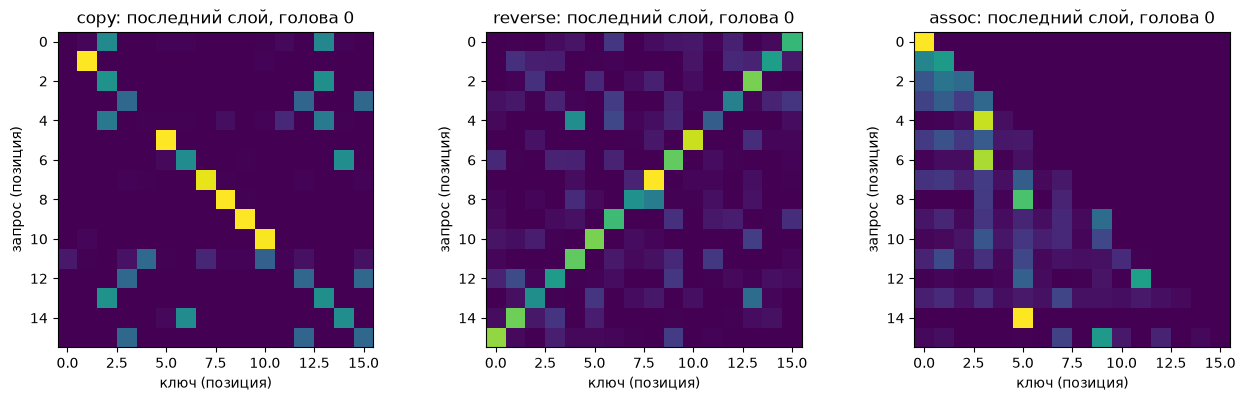

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, task in zip(axes, ["copy", "reverse", "assoc"]):
    m = results[task][0]; x, _, _ = task_batch(task, B=1)
    with torch.no_grad(): m(x)
    ax.imshow(m.layers[-1].last_probs[0, 0], cmap="viridis"); ax.set_title(f"{task}: последний слой, голова 0")
    ax.set_xlabel("ключ (позиция)"); ax.set_ylabel("запрос (позиция)")
plt.tight_layout(); plt.savefig(ARTIFACTS / "lab04_attention_maps.png", dpi=120); plt.show()

### 3б. Масштабирование в обучении

scale=1           final acc = 0.203
scale=1/sqrt(d)   final acc = 1.000
scale=1/d         final acc = 1.000


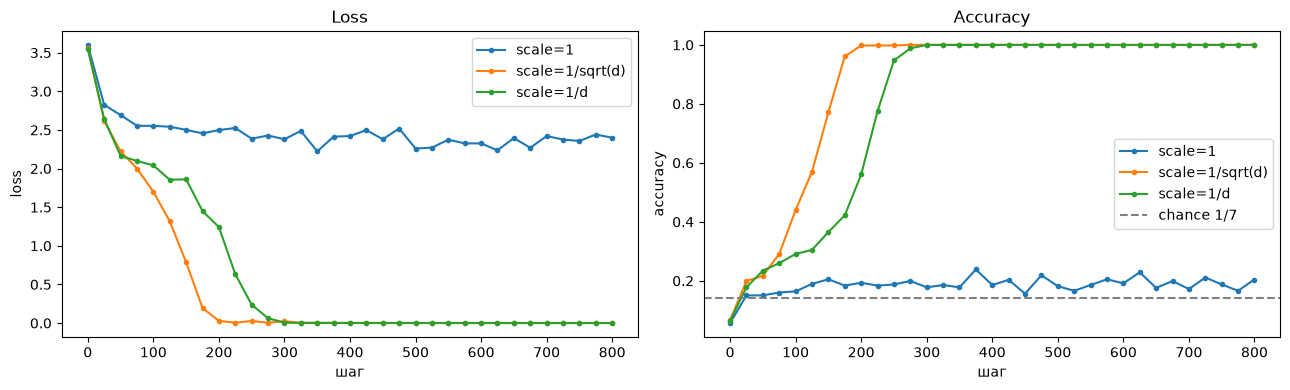

In [ ]:
# (обучите assoc-модели с d_head=64 (d_model=128, 2 головы) при scale = 1, 1/sqrt(d), 1/d и qk_unit_init=True; постройте кривые)

scales = {"1": 1.0, "1/sqrt(d)": 64 ** -0.5, "1/d": 1 / 64}
hist_scales = {}
for name, sc in scales.items():
    set_seed()
    m = AttnOnly(32, 16, d_model=128, n_head=2, n_layer=2,
                 causal=True, scale=sc, qk_unit_init=True)
    hist_scales[name] = train_task(m, "assoc", 2 * STEPS)
    print(f"scale={name:10s}  final acc = {hist_scales[name][-1][2]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, h in hist_scales.items():
    s = [s for s, _, _ in h]; l = [x for _, x, _ in h]; a = [x for _, _, x in h]
    axes[0].plot(s, l, label=f"scale={name}", marker="o", ms=3)
    axes[1].plot(s, a, label=f"scale={name}", marker="o", ms=3)
axes[0].set(xlabel="шаг", ylabel="loss", title="Loss")
axes[1].set(xlabel="шаг", ylabel="accuracy", title="Accuracy")
axes[1].axhline(1 / 7, ls="--", c="gray", label="chance 1/7")
axes[0].legend(); axes[1].legend()
plt.tight_layout(); plt.savefig(ARTIFACTS / "lab04_scaling.png", dpi=120); plt.show()

## 5. Перестановочная эквивариантность

Проверьте, что без позиционных эмбеддингов и без каузальной маски слой attention эквивариантен к перестановкам: \(f(\Pi X) = \Pi f(X)\). Покажите, что с позиционными эмбеддингами или с каузальной маской это свойство нарушается, и объясните, почему без позиционной информации задача разворота не решается.

In [ ]:
# (проверьте эквивариантность для трёх конфигураций)

def perm_equivariance_check(kw, name, T=8, vocab=32):
    set_seed()
    m = AttnOnly(vocab, T, **kw).eval()
    x = torch.randint(vocab, (1, T))
    perm = torch.randperm(T)
    while torch.equal(x[:, perm], x):
        perm = torch.randperm(T)
    with torch.no_grad():
        y = m(x)                # f(X)
        y_p = m(x[:, perm])     # f(ΠX)
    diff = (y_p - y[:, perm]).abs().max().item()
    print(f"{name:32s} |f(ΠX) − Πf(X)|max = {diff:.2e}")
    return diff

x = torch.randint(32, (1, 8))
perm_equivariance_check(dict(n_layer=1, causal=False, use_pos=False), "без позиций / без каузальности")
perm_equivariance_check(dict(n_layer=1, causal=False, use_pos=True), "с позиционными эмбеддингами")
perm_equivariance_check(dict(n_layer=1, causal=True,  use_pos=False), "с каузальной маской")

без позиций / без каузальности   |f(ΠX) − Πf(X)|max = 3.58e-07
с позиционными эмбеддингами      |f(ΠX) − Πf(X)|max = 4.46e-02
с каузальной маской              |f(ΠX) − Πf(X)|max = 4.27e-01


0.42707377672195435

## Вопросы

1. Докажите, что \(\mathrm{Var}(q^\top k) = d_k\) при сделанных предположениях. Какие предположения нарушаются в обученной модели?
2. Почему насыщение softmax вредно именно для обучения, а не для инференса?
3. Почему для разворота достаточно одного слоя, а для ассоциативного поиска с каузальной маской нужно два? Опишите механизм, который реализуют два слоя.
4. Какую сложность по времени и памяти имеет ваша реализация? Какие промежуточные тензоры приходится хранить для обратного прохода?
5. Объясните на основе эксперимента 3б, почему масштаб \(1/d\) (μP-attention) тоже может работать.

Выводы: реализованы scaled dot-product attention с casual и padding маской, а также multi-head attention, результат совпал с scaled_dot_product_attention из библиотеки. Написан backward и сравнён с autograd. Эксперимент с масштабированием подтвердил теорию, что при масштабе дисперсия логитов и норма якобиана softmax остаются стабильными.